# Reproducao no ACDC -- teste de aceitacao dos metodos SSL

**Este notebook nao e um experimento. E o teste de aceitacao do port.**

Os experimentos X1 e X1B perguntam se semi-supervisao ajuda no VFSS. O problema e que nada no
pipeline VFSS distingue *"o port do DiffRect esta quebrado"* de *"DiffRect nao ajuda no VFSS"*:
um retificador com bug produz apenas uma celula X1 um pouco pior, que e exatamente a conclusao
que o X1 deveria **ganhar** e nao **herdar**.

O ACDC resolve isso porque ja tem gabarito publicado. Se a nossa implementacao reproduz os numeros
da Tabela 1 do DiffRect (Liu, Li & Yuan, MICCAI 2024, arXiv:2407.09918), entao um resultado ruim
no VFSS e uma afirmacao sobre o VFSS. Se nao reproduz, e uma afirmacao sobre o nosso codigo.

**Regra de sequenciamento: nao rodar a grade do X1 antes deste notebook fechar.**

---

## O que da para comparar e o que nao da

Nem toda linha da tabela publicada tem correspondente exato aqui. Isso precisa estar explicito,
senao a comparacao vira teatro:

| nosso metodo | linha publicada | comparavel? |
|---|---|---|
| `diffrect` | DiffRect | **Sim, diretamente.** E o alvo do teste. |
| `fixmatch` | FixMatch | Aproximadamente. O nosso `FixMatchLitWrapper` e o FixMatch *canonico* (limiar 0.95, sem complementary loss); a linha publicada usa a variante do SSL4MIS. O `diffrect` usa a variante da referencia via `semi_supervised_base: reference`. |
| `meanteacher` | UAMT | **Nao diretamente.** UAMT e Mean Teacher *com estimativa de incerteza*; o nosso e Mean Teacher puro. Serve como ordem de grandeza, nao como igualdade. |
| `supervised` | (nenhuma) | A linha `Supervised` do artigo usa **100%** dos rotulos (91.48 Dice). Aqui `supervised` roda no mesmo orcamento escasso dos demais -- e o piso que a semi-supervisao precisa superar, nao o teto. |

## Duas divergencias declaradas

1. **HD95 e ASD nao sao bit-identicos aos publicados.** A referencia usa `medpy` (GPL-3.0); este
   repositorio ja recusa dependencia com licenca restritiva (ver `src/models/ssl/base.py`, onde
   `sigmoid_rampup` foi reimplementado para nao puxar CC BY-NC), entao as distancias de superficie
   sao reimplementadas sobre `scipy.ndimage` em `src/metrics.py`. Dice e Jaccard sao operacoes de
   conjunto exatas e devem bater; HD95/ASD dependem de como os voxels de superficie sao extraidos.
2. **Container de dados.** As fatias sao `.npz` por volume e nao `.h5` por fatia. O *conteudo*
   (float32 normalizado min-max por volume, label uint8, indexacao por fatia) e transcrito do
   `acdc_data_processing.py` do SSL4MIS; so o container muda. Ver `scripts/prepare_acdc.py`.

> ACDC e distribuido sob CC BY-NC-SA 4.0. Citar Bernard et al., IEEE TMI 2018.

In [12]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../../")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Parametros

In [2]:
REPO_ROOT = Path("../../").resolve()
CONFIG_DIR = REPO_ROOT / "configs/experiment/acdc"
LOGS_DIR = REPO_ROOT / "logs"
RESULTS_CSV = LOGS_DIR / "acdc" / "results_per_volume.csv"

ACDC_ROOT = Path("/data_ssd/caioseda/data/ACDC")

# Grade. O regime de 1% e o numero de destaque do artigo (82.40 Dice) mas tambem o mais instavel:
# o proprio artigo mostra 82.40 em validacao contra 71.85 em teste para a mesma configuracao. 5% e
# 10% discriminam DiffRect dos baselines com muito menos variancia, entao sao o default. Para
# reproduzir a tabela inteira, use LABEL_RATIOS = ["1%", "5%", "10%"].
LABEL_RATIOS = ["5%", "10%"]
METHODS = ["supervised", "meanteacher", "fixmatch", "diffrect"]
SEEDS = [1337]              # a semente da referencia

# ABLACAO DE BACKBONE. Todo numero publicado de ACDC 2-D e medido na UNet do SSL4MIS: 1.81M
# parametros, dropout de 0.05 a 0.5, larguras [16,32,64,128,256]. A src.models.unet.UNet deste
# repositorio -- a que o X1/X1B usa -- tem 17.26M e nenhum dropout: 9.5x maior. Reproduzir um
# numero trocando o backbone em silencio nao seria reproducao, e rodar so o nosso deixaria
# qualquer diferenca ambigua entre "o port esta errado" e "a arquitetura e outra". Entao rodam
# os dois: "ssl4mis" e o teste de aceitacao, "repo" diz quanto do resultado e arquitetura.
BACKBONES = ["ssl4mis", "repo"]

MAX_STEPS = 30_000          # a referencia treina 30k iteracoes
BATCH_SIZE = 6              # 6 por batch, 3 rotulados
LABELED_BATCH_SIZE = 3
VAL_EVERY_N_STEPS = 500

NUM_CLASSES = 4
CLASS_IDS = {1: "RV", 2: "Myo", 3: "LV"}   # ventriculo direito, miocardio, ventriculo esquerdo
METRICS = ["dice", "jaccard", "hd95", "asd"]

# Custo medido nesta maquina (RTX 6000 Ada, batch 6, 256x256), segundos por passo:
#   supervised 0.045 | meanteacher 0.051 | fixmatch 0.076 | diffrect 0.243  (5.4x o supervisionado)
# 30k passos: ~0.4h / 0.4h / 0.6h / 2.0h. O artigo declara "~2 GPU hours" para o DiffRect numa
# 4090, o que confere. Grade default (2 orcamentos x 4 metodos): ~6.8 h.

RESULTS_CSV.parent.mkdir(parents=True, exist_ok=True)
LOGS_DIR.mkdir(parents=True, exist_ok=True)

## Numeros publicados (DiffRect, Tabela 1)

Transcritos do artigo. Sao o gabarito contra o qual a Parte 3 compara.

In [3]:
# Dice / Jaccard / HD95 / ASD, conjunto de VALIDACAO do ACDC.
PUBLISHED_VAL = pd.DataFrame([
    ("1%",  "UAMT",       42.28, 32.21, 40.74, 18.58),
    ("1%",  "FixMatch",   69.67, 58.34, 37.92, 14.41),
    ("1%",  "CPS",        56.70, 44.31, 24.97, 10.48),
    ("1%",  "ICT",        43.03, 30.58, 34.92, 15.23),
    ("1%",  "MCNetV2",    57.49, 43.29, 31.31, 10.97),
    ("1%",  "INCL",       77.80, 66.13, 11.69,  3.22),
    ("1%",  "DiffRect",   82.40, 71.96, 10.04,  2.90),
    ("5%",  "UAMT",       72.71, 60.89, 21.48,  7.15),
    ("5%",  "FixMatch",   83.12, 73.59,  9.86,  2.61),
    ("5%",  "CPS",        75.24, 64.67, 10.93,  2.98),
    ("5%",  "ICT",        74.20, 62.90, 17.01,  4.32),
    ("5%",  "MCNetV2",    78.96, 68.15, 12.13,  3.91),
    ("5%",  "INCL",       85.43, 75.76,  6.37,  1.37),
    ("5%",  "DiffRect",   86.95, 78.08,  4.07,  1.23),
    ("10%", "UAMT",       85.14, 75.90,  6.25,  1.80),
    ("10%", "FixMatch",   88.31, 79.97,  7.35,  1.79),
    ("10%", "CPS",        84.63, 75.20,  7.57,  2.27),
    ("10%", "ICT",        85.15, 76.05,  4.27,  1.46),
    ("10%", "MCNetV2",    85.97, 77.21,  7.55,  2.11),
    ("10%", "INCL",       88.68, 80.09,  1.67,  0.49),
    ("10%", "DiffRect",   90.18, 82.72,  1.38,  0.48),
    ("100%","Supervised", 91.48, 84.87,  1.12,  0.34),
], columns=["ratio", "method_published", "dice", "jaccard", "hd95", "asd"])

# Conjunto de TESTE (o artigo reporta os dois; a diferenca entre eles em 1% e a razao de 1% nao
# ser o default desta grade).
PUBLISHED_TEST = pd.DataFrame([
    ("1%",  "DiffRect", 71.85, 61.53, 5.79, 2.12),
    ("5%",  "DiffRect", 82.46, 71.76, 7.18, 1.94),
    ("10%", "DiffRect", 89.27, 81.13, 3.85, 1.00),
    ("100%","Supervised", 91.65, 84.95, 1.14, 0.50),
], columns=["ratio", "method_published", "dice", "jaccard", "hd95", "asd"])

# Como cada metodo nosso se mapeia numa linha publicada (None = sem correspondente).
PUBLISHED_COUNTERPART = {"diffrect": "DiffRect", "fixmatch": "FixMatch",
                         "meanteacher": "UAMT", "supervised": None}

PUBLISHED_VAL[PUBLISHED_VAL.ratio.isin(LABEL_RATIOS + ["100%"])].pivot(
    index="method_published", columns="ratio", values="dice")

ratio,10%,100%,5%
method_published,,,
CPS,84.63,NaN,75.24
DiffRect,90.18,NaN,86.95
FixMatch,88.31,NaN,83.12
ICT,85.15,NaN,74.20
INCL,88.68,NaN,85.43
MCNetV2,85.97,NaN,78.96
Supervised,NaN,91.48,NaN
UAMT,85.14,NaN,72.71


---
# Parte 1 -- Dados (sem GPU)

O preparo baixa o ACDC cru do mirror `MedOtter/ACDC` no HuggingFace e reproduz o pre-processamento
do SSL4MIS, usando as listas de split oficiais deles. Isso importa: o split **e** o experimento.

Dois detalhes que o script trata e que sao faceis de errar em silencio:

- **O mirror pode vir incompleto.** Na primeira execucao aqui, o `snapshot_download` retornou
  sucesso tendo pulado dois arquivos (`patient027_frame01.nii.gz` e `patient087_frame01_gt.nii.gz`),
  deixando 199 imagens e 199 mascaras que *nao pareavam*. Contar arquivos nao pegaria -- os totais
  batiam. A verificacao e sobre o pareamento.
- **O SSL4MIS renumera os frames.** O ACDC cru nomeia os dois frames anotados pelo indice no cine
  loop (`patient001` tem `frame01` e `frame12`), mas as listas so contem `_frame01` e `_frame02`.
  `frame01` e a diastole final e `frame02` a sistole final, lidos do `Info.cfg` de cada paciente.
  Inverter isso nao falharia: os dois frames de um paciente sempre caem no mesmo split, entao o
  split continuaria certo. O que mudaria em silencio e `train_slices.list`, cujas primeiras N linhas
  **sao** o subconjunto rotulado dos regimes de 1%/5%/10%.

In [4]:
# Idempotente: pula o download e a conversao do que ja existe.
!python ../../scripts/prepare_acdc.py --root {ACDC_ROOT} --skip-download

Download verified: 200 image/mask pairs.
Converted 200 annotated volumes into /data_ssd/caioseda/data/ACDC/volumes
Verified: 140/20/40 train/val/test volumes, 1312 training slices.

ACDC is distributed under CC BY-NC-SA 4.0. Cite Bernard et al., IEEE TMI 2018.


In [5]:
from src.data.acdc_dataset import (ACDCTrain, ACDCValVolumes, ACDCTestVolumes,
                                   ACDC_LABEL_RATIOS, ACDC_PATIENTS_TO_SLICES)
from src.data.samplers import labeled_unlabeled_indices

audit = []
for ratio in ["1%", "5%", "10%"]:
    patients = ACDC_LABEL_RATIOS[ratio]
    ds = ACDCTrain(root=ACDC_ROOT, labeled_patients=patients, expose_hidden_targets=True)
    labeled, unlabeled = labeled_unlabeled_indices(ds)

    # O SSL4MIS toma os rotulados como `range(0, N)` sobre train_slices.list. Um sorteio aleatorio
    # com a mesma contagem seria OUTRO experimento, com outro conjunto de fatias.
    assert labeled == list(range(len(labeled))), "os rotulados nao sao o prefixo de train_slices.list"
    assert len(labeled) == ACDC_PATIENTS_TO_SLICES[patients]
    assert ds.video_frame_df["is_labeled"].dtype == np.bool_

    audit.append({"orcamento": ratio, "pacientes": patients, "fatias rotuladas": len(labeled),
                  "fatias nao rotuladas": len(unlabeled), "total": len(ds)})

assert len(ACDCValVolumes(root=ACDC_ROOT)) == 20
assert len(ACDCTestVolumes(root=ACDC_ROOT)) == 40
print("volumes: 140 treino / 20 validacao / 40 teste")
pd.DataFrame(audit).set_index("orcamento")

volumes: 140 treino / 20 validacao / 40 teste


,pacientes,fatias rotuladas,fatias nao rotuladas,total
orcamento,,,,
1%,1,32,1280,1312
5%,7,136,1176,1312
10%,14,256,1056,1312


---
# Parte 2 -- Treino

Cada celula da grade roda pelo mesmo `Experiment` que o X1 usa, com os YAMLs de
`configs/experiment/acdc/`. A diferenca para o X1 esta nos hiperparametros: aqui eles seguem a
**referencia** (SGD 0.01 com poly decay 0.9, 30k iteracoes, batch 6/3), porque o que importa e
comparabilidade com um numero publicado. No X1 eles seguem a convencao do repo (AdamW 1e-3,
cosine, 8000 passos), porque la o que importa e comparabilidade *entre metodos*.

A selecao de checkpoint usa `val/dice_volume`, produzido pelo callback
`src.callbacks.VolumetricValidation` -- Dice **volumetrico**, como na referencia. O
`val/dice_score` que o `LitWrapper` loga e por fatia e continua sendo registrado, mas nao e o que
seleciona o modelo. A distancia entre os dois e informativa por si so.

In [6]:
import torch

from src.experiment import Experiment
from src.evaluation_volume import evaluate_volumes, aggregate_volumes
from src.data.acdc_dataset import ACDC_LABEL_RATIOS

METHOD_CONFIG = {method: CONFIG_DIR / f"acdc-unet-{method}.yaml" for method in
                 ["supervised", "fixmatch", "meanteacher", "diffrect"]}

# O YAML ja traz a UNet da referencia; "repo" e uma sobrescrita.
BACKBONE_OVERRIDE = {
    "ssl4mis": None,
    "repo": {"target": "src.models.unet.UNet",
             "params": {"n_channels": 1, "n_classes": 4, "bilinear": True}},
}

def run_id(method: str, backbone: str, ratio: str, seed: int) -> str:
    return f"{method}-{backbone}-{ratio.replace('%', 'pct')}-s{seed}"

def steps_per_epoch(ratio: str) -> int:
    """Batches por epoca. O TwoStreamBatchSampler define a epoca como uma passada pelos rotulados,
    entao ela encolhe com o orcamento: em 1% sao 32//3 = 10 batches, ou seja 3.000 epocas."""
    return max(1, ACDC_PATIENTS_TO_SLICES[ACDC_LABEL_RATIOS[ratio]] // LABELED_BATCH_SIZE)

def build_overrides(method: str, backbone: str, ratio: str, seed: int) -> dict:
    overrides = {
        "name": f"acdc-{run_id(method, backbone, ratio, seed)}",
        "trainer": {"params": {
            "max_steps": MAX_STEPS,
            "check_val_every_n_epoch": max(1, round(VAL_EVERY_N_STEPS / steps_per_epoch(ratio))),
        }},
        "lr_scheduler": {"params": {"total_iters": MAX_STEPS}},
        "data": {"params": {
            "batch_size": BATCH_SIZE,
            "shared_dataset_params": {"root": str(ACDC_ROOT), "expose_hidden_targets": True},
            "train": {"params": {"labeled_patients": ACDC_LABEL_RATIOS[ratio]}},
            "train_batch_sampler": {"params": {
                "batch_size": BATCH_SIZE, "labeled_batch_size": LABELED_BATCH_SIZE, "seed": seed,
            }},
        }},
    }
    if BACKBONE_OVERRIDE[backbone] is not None:
        overrides["model"] = BACKBONE_OVERRIDE[backbone]
    return overrides

pd.DataFrame([{"orcamento": r, "passos/epoca": steps_per_epoch(r),
               "epocas ate 30k": MAX_STEPS // steps_per_epoch(r),
               "validar a cada N epocas": max(1, round(VAL_EVERY_N_STEPS / steps_per_epoch(r)))}
              for r in ["1%", "5%", "10%"]]).set_index("orcamento")

/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


,passos/epoca,epocas ate 30k,validar a cada N epocas
orcamento,,,
1%,10,3000,50
5%,45,666,11
10%,85,352,6


In [7]:
def load_results() -> pd.DataFrame:
    return pd.read_csv(RESULTS_CSV) if RESULTS_CSV.exists() else pd.DataFrame()

def save_results(results: pd.DataFrame) -> None:
    results.to_csv(RESULTS_CSV, index=False)

def train_and_evaluate(method: str, backbone: str, ratio: str, seed: int) -> pd.DataFrame:
    """Treina uma celula e devolve as metricas VOLUMETRICAS por volume, em validacao e teste."""
    experiment = Experiment(config_path=str(METHOD_CONFIG[method]),
                            overrides=build_overrides(method, backbone, ratio, seed),
                            log_dir=LOGS_DIR)
    experiment.run(seed=seed)

    # O Mean Teacher reporta pelo teacher; os demais pelo proprio modelo.
    forward_fn = getattr(experiment.lit_module, "_eval_forward", None)

    frames = []
    for split, dataset_cls in (("val", ACDCValVolumes), ("test", ACDCTestVolumes)):
        # surface_metrics=True apenas aqui: durante o treino o callback mantem desligado porque e
        # uma transformada de distancia por classe por volume, a cada validacao.
        per_volume = evaluate_volumes(
            experiment.lit_module, dataset_cls(root=ACDC_ROOT, image_channels=1),
            num_classes=NUM_CLASSES, class_ids=CLASS_IDS, forward_fn=forward_fn,
            surface_metrics=True,
        )
        per_volume.insert(0, "split", split)
        frames.append(per_volume)

    out = pd.concat(frames, ignore_index=True)
    out["output_dir"] = str(experiment.experiment_run_dir)
    return out

In [8]:
results = load_results()

for seed in SEEDS:
    for backbone in BACKBONES:
        for ratio in LABEL_RATIOS:
            for method in METHODS:
                rid = run_id(method, backbone, ratio, seed)

                if len(results) and (results.run_id == rid).any():
                    print(f"[pula] {rid} (ja em {RESULTS_CSV.name})")
                    continue

                print(f"[treina] {rid}")
                per_volume = train_and_evaluate(method, backbone, ratio, seed)

                per_volume.insert(0, "run_id", rid)
                per_volume.insert(1, "method", method)
                per_volume.insert(2, "backbone", backbone)
                per_volume["ratio"] = ratio
                per_volume["seed"] = seed

                results = pd.concat([results, per_volume], ignore_index=True)
                save_results(results)

print(f"\nConcluido: {results.run_id.nunique()} runs, {len(results)} linhas em {RESULTS_CSV}")

[pula] supervised-ssl4mis-5pct-s1337 (ja em results_per_volume.csv)
[pula] meanteacher-ssl4mis-5pct-s1337 (ja em results_per_volume.csv)
[pula] fixmatch-ssl4mis-5pct-s1337 (ja em results_per_volume.csv)
[pula] diffrect-ssl4mis-5pct-s1337 (ja em results_per_volume.csv)
[pula] supervised-ssl4mis-10pct-s1337 (ja em results_per_volume.csv)
[pula] meanteacher-ssl4mis-10pct-s1337 (ja em results_per_volume.csv)
[pula] fixmatch-ssl4mis-10pct-s1337 (ja em results_per_volume.csv)
[pula] diffrect-ssl4mis-10pct-s1337 (ja em results_per_volume.csv)
[pula] supervised-repo-5pct-s1337 (ja em results_per_volume.csv)
[pula] meanteacher-repo-5pct-s1337 (ja em results_per_volume.csv)
[pula] fixmatch-repo-5pct-s1337 (ja em results_per_volume.csv)
[pula] diffrect-repo-5pct-s1337 (ja em results_per_volume.csv)
[pula] supervised-repo-10pct-s1337 (ja em results_per_volume.csv)
[pula] meanteacher-repo-10pct-s1337 (ja em results_per_volume.csv)
[pula] fixmatch-repo-10pct-s1337 (ja em results_per_volume.csv)
[pul

---
# Parte 3 -- Medido contra publicado

## Tolerancia

O criterio de aceitacao, declarado **antes** de olhar os numeros:

- **Dice do `diffrect` dentro de 2.0 pontos** da linha publicada, em validacao, em cada orcamento
  rodado. Uma reimplementacao independente com semente unica nao reproduz o terceiro decimal; 2
  pontos e menor que a distancia do DiffRect para o segundo colocado (INCL) em 5% (1.52) e em 10%
  (1.50), entao e apertado o suficiente para significar alguma coisa.
- **Jaccard** segue o Dice e nao e um teste independente.
- **HD95 e ASD:** ordem de grandeza e ordenacao entre metodos, nao valor. Sao a metrica
  reimplementada (scipy em vez de medpy) e a mais sensivel a voxels isolados.

Se o `diffrect` passar e o `fixmatch` ficar na faixa da linha publicada dele, o port esta aceito e
a grade do X1 pode rodar.

In [9]:
TOLERANCE_DICE = 2.0   # pontos percentuais

measured = aggregate_volumes(results[results.split == "val"],
                             group_columns=["method", "backbone", "ratio"])
# As metricas saem em [0,1]; a tabela publicada esta em pontos percentuais.
overall = (measured.groupby(["method", "backbone", "ratio"])[METRICS].mean().reset_index())
for metric in ("dice", "jaccard"):
    overall[metric] = overall[metric] * 100

rows = []
for _, row in overall.iterrows():
    counterpart = PUBLISHED_COUNTERPART[row.method]
    published = PUBLISHED_VAL[(PUBLISHED_VAL.ratio == row.ratio) &
                              (PUBLISHED_VAL.method_published == counterpart)]
    entry = {"orcamento": row.ratio, "metodo": row.method, "backbone": row.backbone,
             "linha publicada": counterpart or "--"}
    for metric in METRICS:
        entry[f"{metric} (nosso)"] = round(row[metric], 2)
        entry[f"{metric} (pub)"] = round(published.iloc[0][metric], 2) if len(published) else np.nan
    entry["delta dice"] = (round(entry["dice (nosso)"] - entry["dice (pub)"], 2)
                           if len(published) else np.nan)
    rows.append(entry)

comparison = pd.DataFrame(rows).sort_values(["backbone", "orcamento", "metodo"])
comparison

,orcamento,metodo,backbone,linha publicada,dice (nosso),dice (pub),jaccard (nosso),jaccard (pub),hd95 (nosso),hd95 (pub),asd (nosso),asd (pub),delta dice
0,10%,diffrect,repo,DiffRect,88.57,90.18,80.54,82.72,2.33,1.38,0.51,0.48,-1.61
4,10%,fixmatch,repo,FixMatch,88.48,88.31,80.07,79.97,2.63,7.35,0.63,1.79,0.17
8,10%,meanteacher,repo,UAMT,85.95,85.14,77.17,75.90,3.80,6.25,0.79,1.80,0.81
12,10%,supervised,repo,--,86.78,NaN,78.02,NaN,3.79,NaN,0.76,NaN,NaN
1,5%,diffrect,repo,DiffRect,85.03,86.95,76.13,78.08,2.12,4.07,0.56,1.23,-1.92
5,5%,fixmatch,repo,FixMatch,85.96,83.12,76.59,73.59,4.31,9.86,0.81,2.61,2.84
9,5%,meanteacher,repo,UAMT,82.66,72.71,72.87,60.89,9.44,21.48,2.12,7.15,9.95
13,5%,supervised,repo,--,82.24,NaN,72.37,NaN,11.71,NaN,2.68,NaN,NaN
2,10%,diffrect,ssl4mis,DiffRect,89.54,90.18,81.69,82.72,4.70,1.38,1.03,0.48,-0.64
6,10%,fixmatch,ssl4mis,FixMatch,86.54,88.31,77.50,79.97,9.88,7.35,1.89,1.79,-1.77


In [13]:
# O veredito, explicito.
# O veredito e sobre o backbone da REFERENCIA: e o unico que compara arquiteturas iguais.
verdict = comparison[(comparison.metodo == "diffrect") & (comparison.backbone == "ssl4mis")]
print(f"Criterio: |delta dice| <= {TOLERANCE_DICE} pontos para diffrect, em validacao.\n")
passed = True
for _, row in verdict.iterrows():
    delta = row["delta dice"]
    ok = abs(delta) <= TOLERANCE_DICE
    passed &= ok
    print(f"  {row['orcamento']:>4}  [{row['backbone']}]  nosso {row['dice (nosso)']:6.2f}  "
          f"publicado {row['dice (pub)']:6.2f}  delta {delta:+6.2f}  "
          f"{'PASSA' if ok else 'FALHA'}")

print()
print("PORT ACEITO -- a grade do X1 pode rodar." if passed else
      "PORT REPROVADO -- investigar antes de rodar o X1. Comecar por train/latent_loss e pelo gap "
      "entre train/rectified_dice e train/pseudo_dice no TensorBoard do run que falhou.")

Criterio: |delta dice| <= 2.0 pontos para diffrect, em validacao.

   10%  [ssl4mis]  nosso  89.54  publicado  90.18  delta  -0.64  PASSA
    5%  [ssl4mis]  nosso  86.72  publicado  86.95  delta  -0.23  PASSA

PORT ACEITO -- a grade do X1 pode rodar.


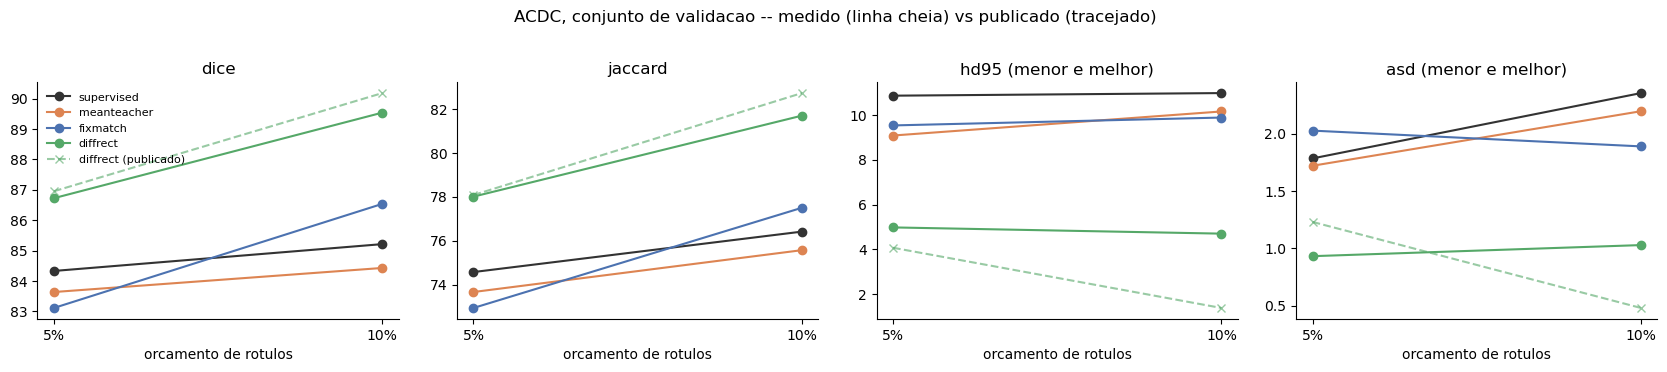

In [15]:
colors = {"supervised": "#333333", "fixmatch": "#4C72B0",
          "meanteacher": "#DD8452", "diffrect": "#55A868"}
ratio_order = [r for r in ["1%", "5%", "10%"] if r in LABEL_RATIOS]
x = np.arange(len(ratio_order))

fig, axes = plt.subplots(1, len(METRICS), figsize=(4.2 * len(METRICS), 3.6))
for ax, metric in zip(np.atleast_1d(axes), METRICS):
    for method in METHODS:
        sub = overall[(overall.method == method) & (overall.backbone == "ssl4mis")].set_index("ratio").reindex(ratio_order)
        ax.plot(x, sub[metric], marker="o", label=method, color=colors[method])

    published = PUBLISHED_VAL[(PUBLISHED_VAL.method_published == "DiffRect") &
                              (PUBLISHED_VAL.ratio.isin(ratio_order))].set_index("ratio")
    ax.plot(x, published.reindex(ratio_order)[metric], marker="x", linestyle="--",
            color=colors["diffrect"], alpha=0.6, label="diffrect (publicado)")

    ax.set_xticks(x); ax.set_xticklabels(ratio_order)
    ax.set_xlabel("orcamento de rotulos")
    ax.set_title(metric + (" (menor e melhor)" if metric in ("hd95", "asd") else ""))
    ax.spines[["top", "right"]].set_visible(False)
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=8)
fig.suptitle("ACDC, conjunto de validacao -- medido (linha cheia) vs publicado (tracejado)", y=1.02)
fig.tight_layout()

## Fatia contra volume

Quanto o Dice por fatia difere do volumetrico. Nao e um teste, e uma leitura: se alguem comparar um
numero deste repositorio com um numero da literatura de ACDC, precisa saber qual dos dois esta
olhando. A diferenca vem das fatias basais e apicais, onde uma classe simplesmente nao existe e a
media por fatia a conta como 0.

In [16]:
per_slice_vs_volume = []
for run_dir in sorted({Path(d) for d in results.output_dir.unique()}):
    metrics_csv = run_dir / "csv" / "metrics.csv"
    if not metrics_csv.exists():
        continue
    log = pd.read_csv(metrics_csv)
    row = {"run": run_dir.parent.name}
    for key, label in (("val/dice_score", "dice por fatia"), ("val/dice_volume", "dice volumetrico")):
        if key in log.columns:
            row[label] = round(float(log[key].dropna().max()) * 100, 2)
    per_slice_vs_volume.append(row)

table = pd.DataFrame(per_slice_vs_volume)
if {"dice por fatia", "dice volumetrico"} <= set(table.columns):
    table["diferenca"] = (table["dice volumetrico"] - table["dice por fatia"]).round(2)
table

,run,dice por fatia,dice volumetrico,diferenca
0,acdc-diffrect-repo-10pct-s1337,81.73,88.57,6.84
1,acdc-diffrect-repo-5pct-s1337,75.80,85.03,9.23
2,acdc-diffrect-ssl4mis-10pct-s1337,82.45,89.54,7.09
3,acdc-diffrect-ssl4mis-5pct-s1337,79.88,86.72,6.84
4,acdc-fixmatch-repo-10pct-s1337,81.73,88.48,6.75
5,acdc-fixmatch-repo-5pct-s1337,77.15,85.96,8.81
6,acdc-fixmatch-ssl4mis-10pct-s1337,79.42,86.54,7.12
7,acdc-fixmatch-ssl4mis-5pct-s1337,75.26,83.11,7.85
8,acdc-meanteacher-repo-10pct-s1337,78.49,85.95,7.46
9,acdc-meanteacher-repo-5pct-s1337,75.71,82.66,6.95


---
## Notas de reprodutibilidade

- **Dados:** ACDC cru do mirror `MedOtter/ACDC` (HuggingFace, CC BY-NC-SA-4.0), pre-processado por
  `scripts/prepare_acdc.py` com as listas de split do SSL4MIS. 140/20/40 volumes, 1312 fatias de
  treino -- os mesmos numeros do DiffRect.
- **Semente:** 1337, a da referencia. Semente unica: este notebook responde "a implementacao esta
  certa?", nao "qual metodo e melhor?". Para a segunda pergunta seriam necessarias varias sementes.
- **Selecao de modelo:** melhor `val/dice_volume`, como na referencia. Reportado em validacao e
  teste; o artigo tambem reporta os dois.
- **O que NAO e reproduzido:** os baselines CPS, ICT, MCNetV2 e INCL nao estao implementados neste
  repositorio. As linhas deles ficam na tabela publicada apenas como referencia de escala.

**Se o teste falhar,** a ordem de investigacao e:

1. `supervised` @10% primeiro -- se ele estiver errado, o dataset ou o avaliador esta errado e nada
   a jusante significa nada.
2. `fixmatch` @5% -- sanidade do caminho de dois fluxos e de pseudo-rotulo.
3. So entao o `diffrect`, olhando `train/latent_loss` (o retificador aprende?) e o gap entre
   `train/rectified_dice` e `train/pseudo_dice` (a retificacao melhora o pseudo-rotulo?). Esse gap
   e o unico numero que diz que o modulo de retificacao esta fazendo alguma coisa; a referencia nao
   tem esse diagnostico.